<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# --- Task 1: Implement Batch GD, SGD, and Momentum from scratch ---
# We define a simple 2D quadratic loss function: f(x, y) = 0.5 * (x^2 + 10 * y^2)
# The gradient is [x, 10 * y]

def loss_func(w):
    return 0.5 * (w[0]**2 + 10.0 * w[1]**2)

def grad_func(w):
    return np.array([w[0], 10.0 * w[1]])

def batch_gradient_descent(w_start, lr, epochs):
    path = [w_start]
    w = np.array(w_start, dtype=float)
    for _ in range(epochs):
        g = grad_func(w)
        w -= lr * g
        path.append(w.copy())
    return np.array(path)

def stochastic_gradient_descent(w_start, lr, epochs, noise_level=0.5):
    path = [w_start]
    w = np.array(w_start, dtype=float)
    for _ in range(epochs):
        # Simulate stochastic noise on the gradient
        g = grad_func(w) + np.random.normal(0, noise_level, size=2)
        w -= lr * g
        path.append(w.copy())
    return np.array(path)

def momentum_descent(w_start, lr, beta, epochs):
    path = [w_start]
    w = np.array(w_start, dtype=float)
    v = np.zeros_like(w)
    for _ in range(epochs):
        g = grad_func(w)
        v = beta * v + lr * g
        w -= v
        path.append(w.copy())
    return np.array(path)

# Initializations for verification
start_point = [4.0, 4.0]
lr = 0.15
epochs = 15

path_gd = batch_gradient_descent(start_point, lr, epochs)
path_sgd = stochastic_gradient_descent(start_point, lr, epochs)
path_mom = momentum_descent(start_point, lr, beta=0.8, epochs=epochs)

print("Scratch implementations completed successfully.")

Scratch implementations completed successfully.


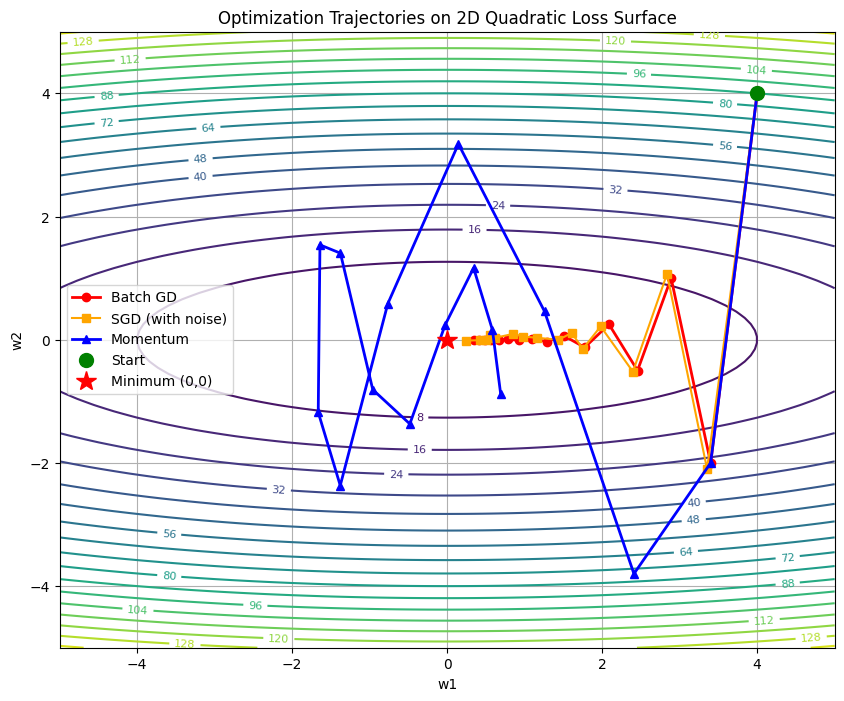

In [2]:
# --- Task 2: Plot each optimizer's path on a 2-D loss contour ---

x_val = np.linspace(-5.0, 5.0, 100)
y_val = np.linspace(-5.0, 5.0, 100)
X, Y = np.meshgrid(x_val, y_val)
Z = 0.5 * (X**2 + 10.0 * Y**2)

plt.figure(figsize=(10, 8))
contour = plt.contour(X, Y, Z, levels=20, cmap='viridis')
plt.clabel(contour, inline=True, fontsize=8)

plt.plot(path_gd[:, 0], path_gd[:, 1], 'o-', color='red', label='Batch GD', linewidth=2)
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 's-', color='orange', label='SGD (with noise)', linewidth=1.5)
plt.plot(path_mom[:, 0], path_mom[:, 1], '^-', color='blue', label='Momentum', linewidth=2)

plt.plot(start_point[0], start_point[1], 'go', markersize=10, label='Start')
plt.plot(0, 0, 'r*', markersize=15, label='Minimum (0,0)')

plt.title('Optimization Trajectories on 2D Quadratic Loss Surface')
plt.xlabel('w1')
plt.ylabel('w2')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# --- Task 3: Train Keras regression models with SGD, SGD+Momentum, and Adam ---
# First, generate a synthetic delivery dataset
np.random.seed(42)
tf.random.set_seed(42)

n_samples = 1000
distance = np.random.uniform(5, 50, n_samples)
traffic_index = np.random.uniform(1, 10, n_samples)
weight = np.random.uniform(1, 20, n_samples)
time_of_day = np.random.uniform(6, 22, n_samples)

# True Delivery Time: a noisy linear combination
delivery_time = (0.8 * distance + 2.5 * traffic_index + 0.3 * weight - 0.1 * time_of_day +
                 10 + np.random.normal(0, 2, n_samples))

X_data = np.stack([distance, traffic_index, weight, time_of_day], axis=1)
y_data = delivery_time.reshape(-1, 1)

# Standardize features for better convergence
X_mean = X_data.mean(axis=0)
X_std = X_data.std(axis=0)
X_data_scaled = (X_data - X_mean) / X_std

def build_model():
    model = keras.Sequential([
        layers.Dense(16, activation='relu', input_shape=(4,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(1)
    ])
    return model

# Clone and compile models for each optimizer
model_sgd = build_model()
model_sgd.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01), loss='mse')

model_momentum = build_model()
model_momentum.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), loss='mse')

model_adam = build_model()
model_adam.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse')

# Train the models
epochs_train = 40
batch_size = 32

history_sgd = model_sgd.fit(X_data_scaled, y_data, epochs=epochs_train, batch_size=batch_size, verbose=0)
history_momentum = model_momentum.fit(X_data_scaled, y_data, epochs=epochs_train, batch_size=batch_size, verbose=0)
history_adam = model_adam.fit(X_data_scaled, y_data, epochs=epochs_train, batch_size=batch_size, verbose=0)

print("Model training completed.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model training completed.


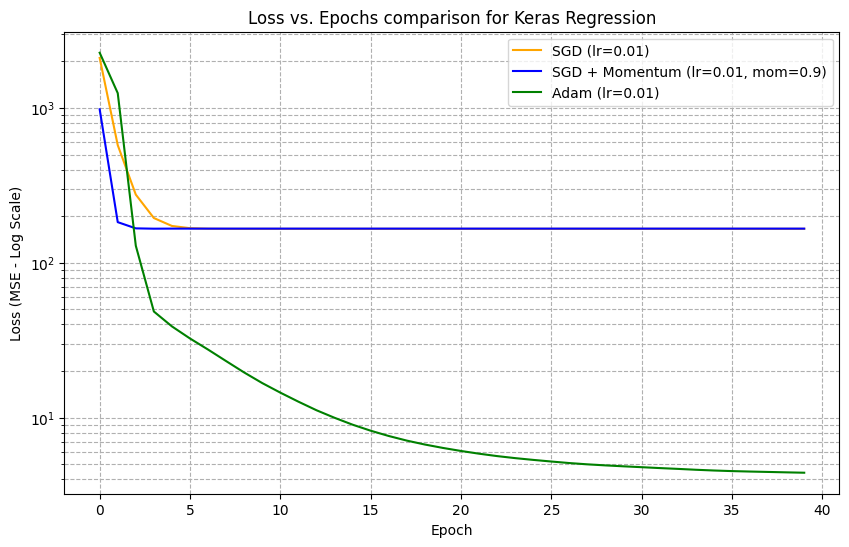

In [4]:
# --- Task 4: Plot loss against epochs for all optimizers ---

plt.figure(figsize=(10, 6))
plt.plot(history_sgd.history['loss'], label='SGD (lr=0.01)', color='orange')
plt.plot(history_momentum.history['loss'], label='SGD + Momentum (lr=0.01, mom=0.9)', color='blue')
plt.plot(history_adam.history['loss'], label='Adam (lr=0.01)', color='green')

plt.yscale('log')
plt.title('Loss vs. Epochs comparison for Keras Regression')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE - Log Scale)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

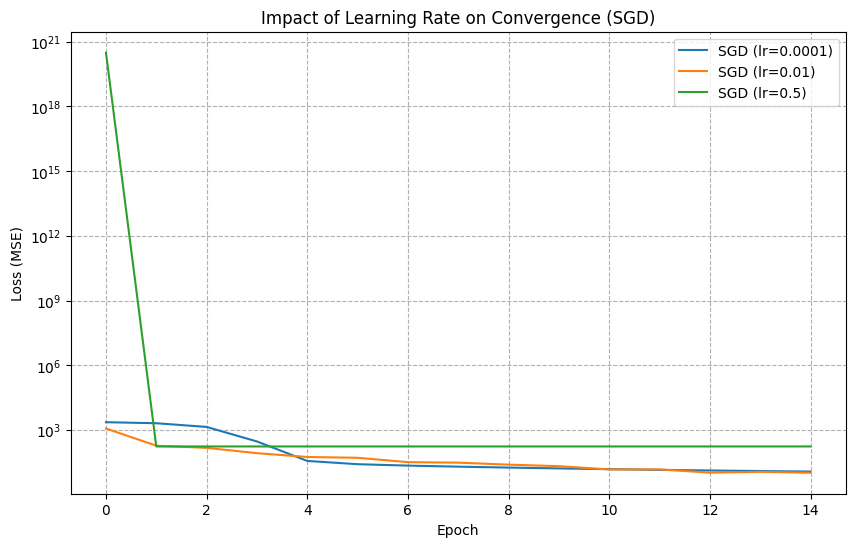

Observations:
- lr=0.0001: Convergence is very slow.
- lr=0.01: Smooth and steady convergence.
- lr=0.5: Oscillations or risk of total divergence (exploding losses).


In [5]:
# --- Task 5: Vary the learning rate and note divergence or slow convergence ---

learning_rates = [0.0001, 0.01, 0.5]
histories_lr = {}

for lr in learning_rates:
    model_temp = build_model()
    # Using standard SGD optimizer to demonstrate the impact of learning rate
    model_temp.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss='mse')
    history = model_temp.fit(X_data_scaled, y_data, epochs=15, batch_size=32, verbose=0)
    histories_lr[lr] = history.history['loss']

# Plot the results
plt.figure(figsize=(10, 6))
for lr, losses in histories_lr.items():
    plt.plot(losses, label=f'SGD (lr={lr})')

plt.title('Impact of Learning Rate on Convergence (SGD)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.yscale('log')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

print("Observations:")
print("- lr=0.0001: Convergence is very slow.")
print("- lr=0.01: Smooth and steady convergence.")
print("- lr=0.5: Oscillations or risk of total divergence (exploding losses).")